# Vectors

Last time we saw how to use an **augmented matrix** and row operations that preserve the relationships in a system to solve a system of linear functions.

A matrix is ultimately a way to represent a table of numbers. Most of the matrices we worked with last time had 2 rows and 3 columns. Here is the first one, setting up our linear system

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

That's a $2x3$ matrix, and by convention we count rows first and then columns - this is also reflected in the way we access a matrix via NumPy or tables in Pandas.


Each of the rows and columns in this matrix is represented as a **list** of numbers. A list of numbers is known as a **vector**. A row from a matrix is known as a row vector, while a column is known as a column vector. Here are the row vectors:


  \begin{bmatrix}
    150 & -1 & -1000\\
  \end{bmatrix}

\\

  \begin{bmatrix}
    200 & -1 & -500\\
  \end{bmatrix}

And here is our column vector:

\begin{bmatrix}
150\\
200\\
\end{bmatrix}

\begin{bmatrix}
-1\\
-1\\
\end{bmatrix}

\begin{bmatrix}
-1000\\
-500\\
\end{bmatrix}

In this section we'll learn more about column vectors and what you can "do with them", which should help us understand certain properties of linear systems.

We finish by reinforcing the approach we used last time to solve the linear system, by combining key ideas around matrices and vectors.

We start by building a geometric intuition for vectors. Generally, the word vector refers to the column vector (as an ordered list of elements in a single column), and we will refer to the column vector this way for the rest of the course.

> **Note:** This notebook contains cells that fail *on purpose*. Cells marked **⚠️ Expected error** are meant to fail so we can practise reading error messages. All other cells should run from top to bottom without errors.


> ### Today's lesson
> * **Topic**: Vectors and matrices in Python.
> * **Mathematics**: vectors geometrically, addition/subtraction, scalar multiplication, the dot product, linear combinations.
> * **Python today**: `plt.quiver`, `.reshape(-1, 1)`, `.dot()`/`@`, elementwise operations.
> * **Supplement**: if needed, revisit *Supplement C - Lists, arrays, dictionaries and tuples*.
> * **Remember**: Run the cells from top to bottom. If something behaves strangely: *Runtime → Restart session and run all*.



When a vector contains 2 or 3 elements, we can easily visualize it in a 2D or 3D coordinate system.

A vector is typically visualized in a coordinate system using arrows rather than coordinates (points). For a vector containing two elements, the first value describes $x$ while the second describes $y$. Vectors are usually drawn from the starting point, or origin, $(0,0)$ to the point described by the vector:

\begin{bmatrix}
3\\
4\\
\end{bmatrix}

\begin{bmatrix}
-1\\
-1\\
\end{bmatrix}

\begin{bmatrix}
-4\\
7\\
\end{bmatrix}

In [1]:
# packages
import matplotlib.pyplot as plt
import numpy as np

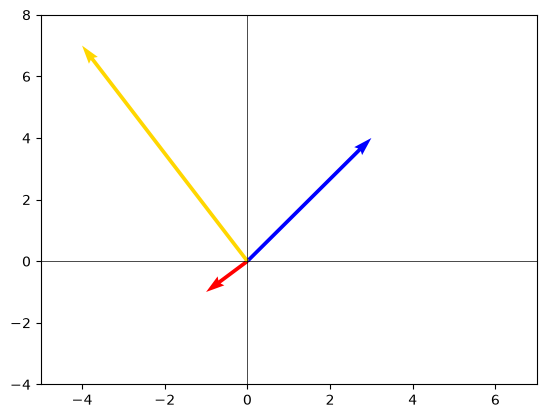

In [2]:
# coordinate system

plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-5,7)
plt.ylim(-4,8)

# vectors

plt.quiver(0, 0, 3, 4, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(0, 0, -1, -1, angles='xy', scale_units='xy', scale=1, color='red')
plt.quiver(0, 0, -4, 7, angles='xy', scale_units='xy', scale=1, color='gold')

Arrows are used to visualize individual vectors because they emphasize the two key properties of a vector - **direction** and **length**.
The direction of a vector describes which way it points, and the length should be self-explanatory.

In the following visualizations you'll find examples of 2 vectors with the same direction but different magnitude, and 2 examples of vectors with the same magnitude but different directions.

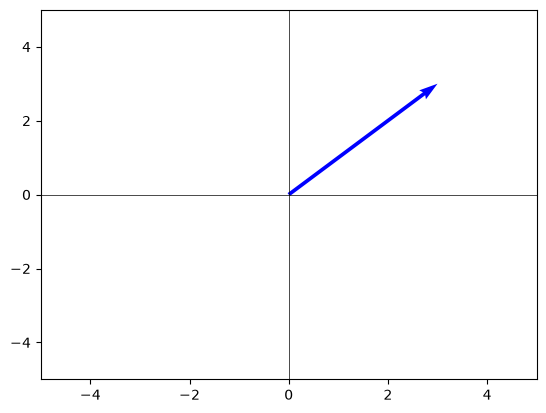

In [3]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-5,5)
plt.ylim(-5,5)

plt.quiver(0, 0, 3, 3, angles='xy', scale_units='xy', scale=1, color='blue')

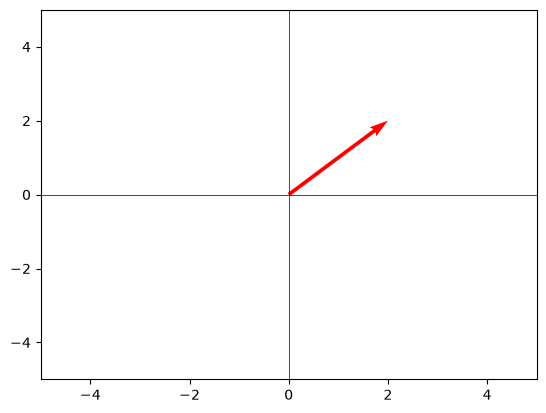

In [4]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-5,5)
plt.ylim(-5,5)

plt.quiver(0, 0, 2, 2, angles='xy', scale_units='xy', scale=1, color='red')

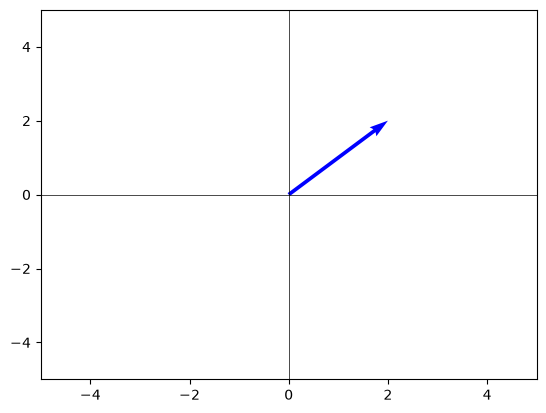

In [5]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-5,5)
plt.ylim(-5,5)

plt.quiver(0, 0, 2, 2, angles='xy', scale_units='xy', scale=1, color='blue')

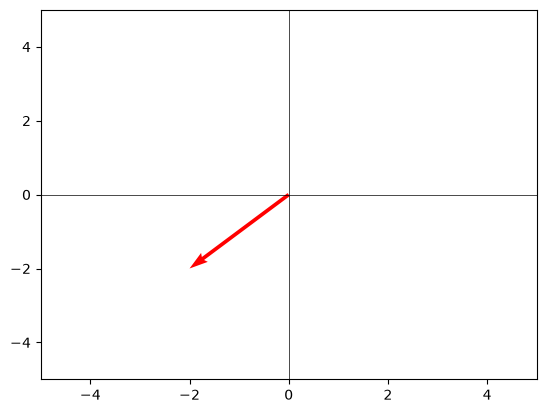

In [6]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-5,5)
plt.ylim(-5,5)

plt.quiver(0, 0, -2, -2, angles='xy', scale_units='xy', scale=1, color='red')

As you can see in the code, we can visualize vectors with `plt.quiver()`
For now we'll always use `angles='xy', scale_units='xy', scale=1` as parameters here,
We can use `color='red'` to set a color...

Exercise: Try to visualize - remember to adjust the coordinate system

\begin{bmatrix}
6\\
2\\
\end{bmatrix}

\begin{bmatrix}
-3\\
-1\\
\end{bmatrix}

\begin{bmatrix}
-4\\
10\\
\end{bmatrix}

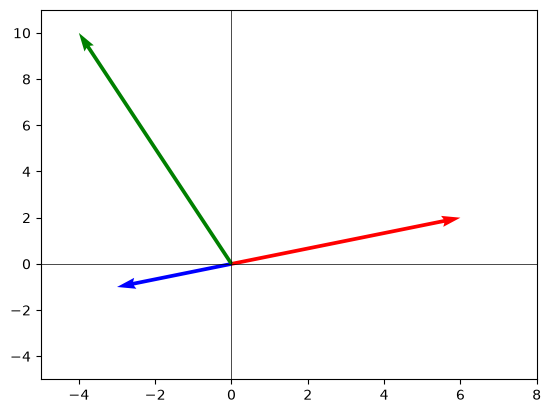

In [7]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-5,8)
plt.ylim(-5,11)

plt.quiver(0, 0, 6, 2, angles='xy', scale_units='xy', scale=1, color='red')
plt.quiver(0, 0, -3, -1, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(0, 0, -4, 10, angles='xy', scale_units='xy', scale=1, color='green')

**addition**

Just like rows in a matrix, vectors can be added together and subtracted. When we add or subtract vectors, elements in the same position are added or subtracted, forming a new vector. Here is an example where two vectors are added:

$$
\begin{bmatrix}
5\\
1
\end{bmatrix} + \begin{bmatrix}
1\\
3
\end{bmatrix} =
\begin{bmatrix}
6\\
4
\end{bmatrix}
$$


\\
To visualize vector addition, you "connect" the vectors instead of visualizing all the vectors from $(0,0)$.

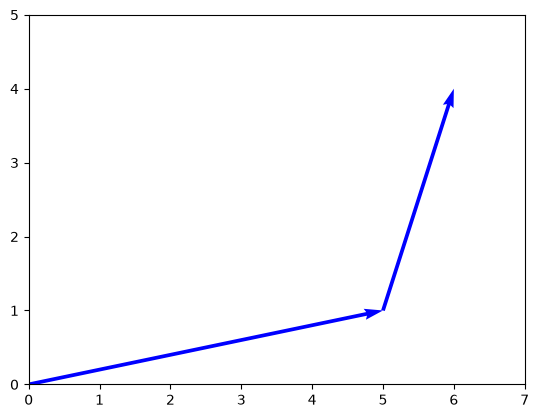

In [8]:
plt.xlim(0,7)
plt.ylim(0,5)

plt.quiver(0, 0, 5, 1, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(5, 1, 1, 3, angles='xy', scale_units='xy', scale=1, color='blue')

as you can see, vector 1 starts at $(0,0)$ while vector two starts at $(5,1)$, where vector 1 ends.

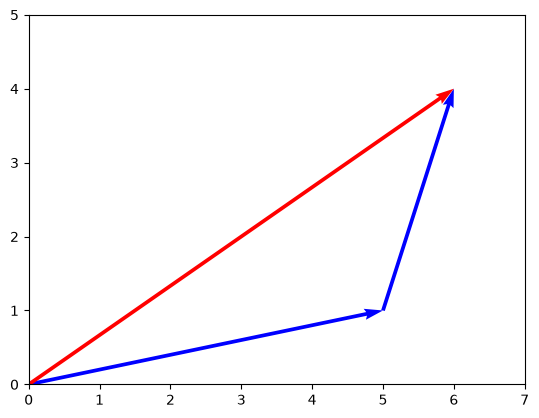

In [9]:
plt.xlim(0,7)
plt.ylim(0,5)

plt.quiver(0, 0, 5, 1, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(5, 1, 1, 3, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(0, 0, 6, 4, angles='xy', scale_units='xy', scale=1, color='red')

The same (just reversed) applies to **subtracting** vectors:


$$
\begin{bmatrix}
5\\
1
\end{bmatrix} - \begin{bmatrix}
1\\
3
\end{bmatrix} =
\begin{bmatrix}
4\\
-2
\end{bmatrix}
$$

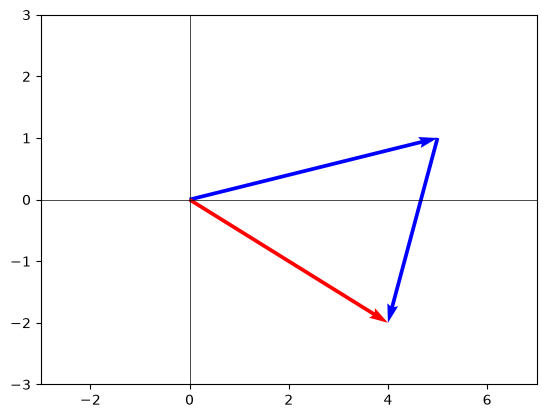

In [10]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-3,7)
plt.ylim(-3,3)

plt.quiver(0, 0, 5, 1, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(5, 1, -1, -3, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(0, 0, 4, -2, angles='xy', scale_units='xy', scale=1, color='red')


Exercise: Visualize

$$
\begin{bmatrix}
5\\
2
\end{bmatrix} + \begin{bmatrix}
2\\
3
\end{bmatrix} =
\begin{bmatrix}
7\\
5
\end{bmatrix}
$$

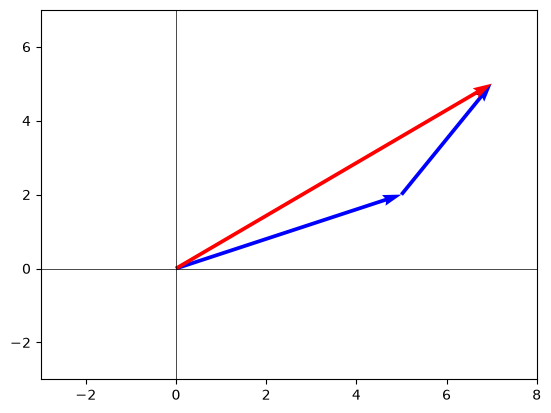

In [11]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-3,8)
plt.ylim(-3,7)

plt.quiver(0, 0, 5, 2, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(5, 2, 2, 3, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(0, 0, 7, 5, angles='xy', scale_units='xy', scale=1, color='red')


**Multiplying vectors**

We can also scale vectors by multiplying or dividing by a scalar (a real number). When we do this, every element of the vector is multiplied or divided by the scalar:

$$
4* \begin{bmatrix}
5\\
2
\end{bmatrix} =
\begin{bmatrix}
20\\
8
\end{bmatrix}
$$


Combining these arithmetic rules makes it possible to combine vectors to obtain new ones. This is one of the central ideas of linear algebra:

$$
4* \begin{bmatrix}
5\\
2
\end{bmatrix} -
\begin{bmatrix}
6\\
3
\end{bmatrix}=
\begin{bmatrix}
14\\
5
\end{bmatrix}
$$

In [12]:
# or with numpy (quick and dirty)
4*np.array([5,2])-np.array([6,3])

array([14,  5])

#### about `shape`

`shape` shows us the form of an array: how many rows/columns are in a matrix. In this course, we normally represent a vector as an ordinary one-dimensional NumPy array — its shape is $(n,)$, e.g. `(3,)` for a vector with three numbers (note: that is *not* the same as $(1,n)$, which is a matrix with one row).
A true column vector (a matrix with one column) has shape $(n,1)$. Writing it directly in Python isn't convenient because you'd have to write `[[1], [2], [3]]` - instead you can use `reshape(-1,1)` to reshape a one-dimensional array into a column vector.

In [13]:
#define vector 1 and turn into a column
v1 = np.array([2,1,2], dtype=np.float32)
v1 = v1.reshape(-1,1)

#define vector 2 and turn into a column
v2 = np.array([3,3,1], dtype=np.float32)
v2 = v2.reshape(-1,1)

v_result = v1*4 - v2*2

In [14]:
v_result

array([[ 2.],
       [-2.],
       [ 6.]], dtype=float32)

In [15]:
v_result.shape

(3, 1)

Without transformation

In [16]:
v11 = np.array([2,1,2], dtype=np.float32)

In [17]:
v22 = np.array([3,3,1], dtype=np.float32)

In [18]:
v_result2 = v11*4 - v22*2

In [19]:
v_result2

array([ 2., -2.,  6.], dtype=float32)

In [20]:
v_result2.shape

(3,)

Why reshape can be important

In [21]:
v_result3 = v11*4 - v2*2

In [22]:
v_result3

array([[ 2., -2.,  2.],
       [ 2., -2.,  2.],
       [ 6.,  2.,  6.]], dtype=float32)

In [23]:
v_result3.shape

(3, 3)

The last important vector operation is the dot product/scalar product.
It's not possible to multiply vectors directly.
The dot product resembles multiplication, but the elements of the vectors are multiplied in a specific way.
Both vectors must contain the same number of elements, which is a requirement the other operations we've learned so far also have.
To compute the dot product, we sum the products of the 2 values at each position in each vector:

$$\vec{a} \cdot \vec{b} = \sum_{i=1}^{n} a_i b_i = a_1b_1 + a_2b_2 + ... + a_nb_n$$

$$
\begin{bmatrix}
2\\
1\\
2
\end{bmatrix} *
\begin{bmatrix}
3\\
3\\
1
\end{bmatrix}= (2·3)+(1·3)+(2·1) = 11
$$

In [24]:
# This is elementwise multiplication - NOT the dot product
np.array([2,1,2]) * np.array([3,3,1])

array([6, 3, 2])

In [25]:
# correct
np.array([2,1,2]).dot(np.array([3,3,1]))

np.int64(11)

In [26]:
# Also correct
np.array([2,1,2]) @ np.array([3,3,1])

np.int64(11)

In [27]:
# or:

a = np.array([2,1,2]).reshape(-1,1)
b = np.array([3,3,1]).reshape(-1,1)

a[:,0]@b

array([11])

In [28]:
# or

np.dot(a[:,0],b)

array([11])

In [29]:
a

array([[2],
       [1],
       [2]])

In [30]:
# or
from sympy import Matrix # import what we need from SymPy
from sympy.matrices import Matrix #import matrix

M = Matrix([2,1,2])
N = Matrix([3,3,1])

M.dot(N)

11

Unlike the other vector operations, the result here is a scalar value, not a vector. Even though we won't put the dot product to use right away, it will be central in the next session, when we learn how to multiply a matrix and a vector together.

So far we've seen that we can multiply vectors by a scalar value and combine vectors using +/-.

Using these operations, we can determine whether a particular vector can be obtained by combining other vectors. For example, we might want to know whether we can combine the vectors $\begin{bmatrix} 2\\ 3 \end{bmatrix}$ and $\begin{bmatrix} 3\\ 1 \end{bmatrix}$ to obtain $\begin{bmatrix} 1\\ 5 \end{bmatrix}$

We can write our problem as:

$$c_1 \begin{bmatrix} 2\\ 3 \end{bmatrix} + c_2 \begin{bmatrix} 3\\ 1 \end{bmatrix}  = \begin{bmatrix} 1\\ 5 \end{bmatrix}$$

$c_1$ and $c_2$ are variables that scale our vectors, and we want to find a solution where our equation holds.

Being able to scale vectors using scalar multiplication and then add or subtract these scaled vectors is known as a **linear combination**.

This concept is essential for applying linear algebra to solve useful problems. Using the concept of linear combination, we can reformulate our problem as follows:

is $\begin{bmatrix} 1\\ 5 \end{bmatrix}$ a linear combination of $\begin{bmatrix} 3\\ 1 \end{bmatrix}$ and $\begin{bmatrix} 2\\ 3 \end{bmatrix}$?

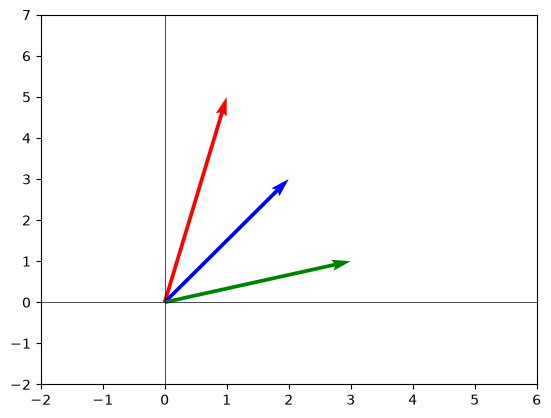

In [31]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-2,6)
plt.ylim(-2,7)

plt.quiver(0, 0, 1, 5, angles='xy', scale_units='xy', scale=1, color='red')
plt.quiver(0, 0, 2, 3, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(0, 0, 3, 1, angles='xy', scale_units='xy', scale=1, color='green')


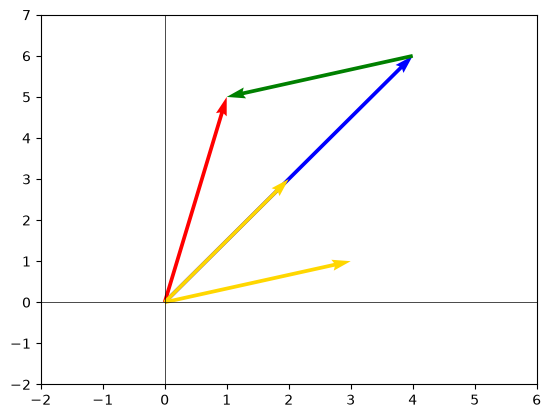

In [32]:
plt.axhline(0, c='black', lw=0.5)
plt.axvline(0, c='black', lw=0.5)
plt.xlim(-2,6)
plt.ylim(-2,7)

plt.quiver(0, 0, 4, 6, angles='xy', scale_units='xy', scale=1, color='blue')
plt.quiver(4, 6, -3, -1, angles='xy', scale_units='xy', scale=1, color='green')
plt.quiver(0, 0, 1, 5, angles='xy', scale_units='xy', scale=1, color='red')

plt.quiver(0, 0, 2, 3, angles='xy', scale_units='xy', scale=1, color='gold')
plt.quiver(0, 0, 3, 1, angles='xy', scale_units='xy', scale=1, color='gold')


$c_1 = 2$; $c_2 = -1$

Last time we looked at salary optimization and ended up writing the 2 equations representing the job offers in matrix form:

**augmented matrix**

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

**now we can try to connect this matrix to the idea of linear combination we just saw**

We would now like to know whether $\begin{bmatrix} -1000\\ -500 \end{bmatrix}$ is a linear combination of $\begin{bmatrix} 150\\ 200 \end{bmatrix}$ and $\begin{bmatrix} -1\\ -1 \end{bmatrix}$

to find the solution, we need to find values for $x$ and $y$ such that the following holds:

$$x \begin{bmatrix} 150\\ 200 \end{bmatrix} + y \begin{bmatrix} -1\\ -1 \end{bmatrix} = \begin{bmatrix} -1000\\ -500 \end{bmatrix}$$

Last time we found a solution using row operations until we arrived at:

$$\left[\begin{array}{rr|r}
1 & 0 & x = 10\\
0 & 1 & y = 2500
\end{array}\right]$$

The last concept we briefly introduce here is the matrix equation. The matrix equation is the representation of a linear system using only matrices and vectors. Here is the augmented matrix we started with:

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

which is shorthand for

$$\left[\begin{array}{rr|r}
150 & -1 \\
200 & -1
\end{array}\right] \begin{bmatrix} x\\ y \end{bmatrix} =  \begin{bmatrix} -1000\\ -500 \end{bmatrix}$$


On the left side, we multiply a matrix of coefficients by the vector containing the variables.

The right side holds the constant values.

This separation of coefficients and variables from the constants should be familiar. This is exactly what we also did in the general form!


We typically use $x_1,x_2,...x_n$ instead of $x,y$ when representing individual values of a solution vector. This gives us the ability to work with as many values as we like (not just ~26).

$$\left[\begin{array}{rr|r}
150 & -1 \\
200 & -1
\end{array}\right] \begin{bmatrix} x_1\\ x_2 \end{bmatrix} =  \begin{bmatrix} -1000\\ -500 \end{bmatrix}$$


We can now also introduce the arithmetic representation of the matrix equation: $A\vec{x} = \vec{b}$


Where $A$ represents the coefficient matrix, $\vec{x}$ represents the solution vector, and $\vec{b}$ represents the constants. NOTE $\vec{b}$ cannot be a vector holding only zeros, also known as the zero vector $\vec{0}$.

Before we can work with this form of system, we need to learn about the following topics in the next section:

- rules describing how matrices can be combined
- how to multiply a matrix by a vector
- how to compute the solution vector $\vec{x}$
 without using Gaussian elimination.

# Matrices

Just like vectors, matrices have their own set of algebraic operations. In this part we will learn about the most central matrix operations and build up to using some of them to solve matrix equations.

Let's first start with matrix addition and subtraction.

As we discussed earlier, a matrix consists of one or more column vectors.

Matrix:
$$
\left[
  \begin{matrix}
    0.5 & 2 & 3 \\
    1.4 & 4 & 4 \\
    0.3 & 7 & 1 \\
  \end{matrix}
\right]
$$

$$
\swarrow
\downarrow
\searrow
$$

Column vectors:

$$
\left[ \begin{array}{cc}
0.5 \\
1.4 \\
0.3
\end{array} \right]
%
\left[ \begin{array}{cc}
2 \\
4 \\
7
\end{array} \right]
%
\left[ \begin{array}{cc}
3 \\
4 \\
1
\end{array} \right]
$$

Because of this, we can carry the vector operations over to matrices too. We can
perform vector addition and subtraction between vectors with the same number of rows.
We can only perform matrix addition and subtraction between matrices that contain the same number of rows and columns. `M1.shape == M2.shape`


Valid summation:
$$
  \begin{bmatrix}
    0.5 & 2 \\
    1.4 & 4 \\
  \end{bmatrix}
+
  \begin{bmatrix}
    4 & 4 \\
    7 & 1 \\
  \end{bmatrix}
 %
 \hspace{1cm}
  \begin{bmatrix}
    0.5 & 2 \\
    7 & 1.7 \\
    2 & 5
  \end{bmatrix}
+
  \begin{bmatrix}
    0.5 & 2 \\
    7 & 1.7 \\
    2 & 5
  \end{bmatrix}
$$

No Go 🚫:
$$
  \begin{bmatrix}
    0.5 & 3 & 5 \\
    1.4 & 3 & 9 \\
  \end{bmatrix}
+
  \begin{bmatrix}
    1 \\
    4 \\
    1
  \end{bmatrix}
$$

In [33]:
M1 = np.array([[0.5,2],
              [1.4,4]])

M2 = np.array([[4,4],
               [7,1]])

M3 = np.array([1,4,1])

In [34]:
M1 + M2

array([[4.5, 6. ],
       [8.4, 5. ]])

In [35]:
# ⚠️ Expected error — this cell is supposed to fail
M1 + M3

ValueError: operands could not be broadcast together with shapes (2,2) (3,) 

Just like with vectors, matrix addition and subtraction work by distributing the operations across the specific elements and combining them.


In [36]:
M1 = np.array([[6,2,4],[3.5,5,7],[5,3,2]])
M2 = np.array([[0, 3.4, 2],[3,0.2,1],[0.1, 1.1, 7]])

M1 + M2

array([[6. , 5.4, 6. ],
       [6.5, 5.2, 8. ],
       [5.1, 4.1, 9. ]])

## Remember:



*   When we talk about matrices, we count rows first and then columns - a $2x3$ matrix has 2 rows and 3 columns.
*   A list of numbers from a matrix is a vector. A row - a row vector, a column - a column vector
* A vector is often visualized using arrows starting at $(0,0)$ to emphasize length and direction as its properties.
* Just like rows in a matrix, we can also add and subtract vectors. You can also scale vectors up by multiplying by numbers > 1 and < -1; and down by multiplying by numbers between -1 and 1.
* the dot product is computed by summing the products of the 2 values at every position in the vectors being multiplied. $$\vec{a} \cdot \vec{b} = \sum_{i=1}^{n} a_i b_i = a_1b_1 + a_2b_2 + ... + a_nb_n$$

* A linear combination is vectors that have been scaled and then added together or subtracted.

* The arithmetic representation of the matrix equation is $A\vec{x} = \vec{b}$ where $A$ represents the coefficient matrix, $\vec{x}$ represents the solution vector, and $\vec{b}$ represents the constants. NOTE $\vec{b}$ cannot be a vector holding only zeros, also known as the zero vector $\vec{0}$.







$$
A + B =
  \begin{smallmatrix} \textrm{A}\\\begin{bmatrix}
    6 & 2 & 4 \\
    3.5 & 5 & 7 \\
    5 & 3 & 2
  \end{bmatrix}\end{smallmatrix}
+
 \begin{smallmatrix} \textrm{B}\\\begin{bmatrix}
    0 & 3.4 & 2 \\
    3 & 0.2 & 1 \\
    0.1 & 1.1 & 7 \\
  \end{bmatrix}\end{smallmatrix}
=
\begin{smallmatrix} \textrm{A+B}\\\begin{bmatrix}
    6 & 5.4 & 6 \\
    6.5 & 5.2 & 8 \\
    5.1 & 4.1 & 9 \\
  \end{bmatrix}\end{smallmatrix}
$$